# Оценка стоимости домов: линейная регрессия

**Задача.** По характеристикам дома оценить цену его продажи и понять, какие
характеристики и насколько влияют на стоимость.

**Данные.** Продажи жилой недвижимости в округе Кинг (Сиэтл, штат Вашингтон) за
2006–2015 годы: 22 687 сделок, `data/raw/house_sales.csv`.

**План.**
1. Данные.
2. Простая линейная регрессия: цена и жилая площадь.
3. Множественная регрессия: коэффициенты, RMSE, R², статистическая таблица.
4. Отбор признаков: полная модель и пошаговый отбор по AIC.
5. Взвешенная регрессия.
6. Категориальные признаки: тип недвижимости и почтовые индексы.
7. Интерпретация: коррелированные признаки, смешивающий фактор, взаимодействия.
8. Диагностика регрессии: выбросы, влиятельные наблюдения, гетероскедастичность,
   частные остатки.
9. Нелинейность: полином, сплайны, GAM.
10. Регуляризация: Lasso.
11. Сравнение моделей на отложенной выборке.
12. Итоги.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from cycler import cycler
from pygam import LinearGAM, l, s
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.gam.api import BSplines, GLMGam
from statsmodels.stats.outliers_influence import OLSInfluence

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
HOUSE_CSV = ROOT / "data" / "raw" / "house_sales.csv"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

# pyGAM.summary() предупреждает, что p-значения в его таблице занижены; выводы по ним не делаются
warnings.filterwarnings("ignore", message="KNOWN BUG: p-values")

# Стиль графиков
PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
       "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9",
       "axis": "#c3c2b7", "surface": "#fcfcfb"}
BLUE_RAMP = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]
plt.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"], "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": PAL["axis"], "axes.labelcolor": PAL["ink2"], "text.color": PAL["ink"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["muted"],
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.prop_cycle": cycler(color=[PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"]]),
    "lines.linewidth": 2, "legend.frameon": False,
})
def _usd(v, _):
    sign, v = ("−" if v < 0 else ""), abs(v)
    return f"{sign}${v / 1e6:.1f}M" if v >= 1e6 else f"{sign}${v / 1e3:.0f}K"


USD = mticker.FuncFormatter(_usd)


def style_points(ax, color=PAL["blue"], size=3.5):
    """Приводит точки встроенных графиков statsmodels к общему стилю."""
    for line in ax.lines:
        if line.get_marker() not in (None, "None", ""):
            line.set(color=color, markersize=size, alpha=0.5, markeredgewidth=0)
        else:
            line.set(color=PAL["ink"], linewidth=2)


def save(fig, name):
    """Сохраняет график в reports/figures и выводит его."""
    fig.savefig(FIG / f"{name}.png")
    plt.show()


def print_coefs(intercept, names, coefs):
    print(f"Свободный член: {intercept:,.0f}")
    for name, coef in zip(names, coefs):
        print(f"  {name}: {coef:,.2f}")

## 1. Данные

| Столбец | Описание |
|---|---|
| `DocumentDate` | дата сделки |
| `SalePrice` | цена продажи, $ |
| `zhvi_idx` | индекс цен на жильё Zillow относительно мая 2015 года (= 1) |
| `AdjSalePrice` | **целевая переменная**: `SalePrice / zhvi_idx` — цена в ценах мая 2015 года |
| `PropertyType` | тип: `Single Family` (дом на одну семью), `Townhouse` (таунхаус), `Multiplex` (дом на несколько квартир) |
| `SqFtTotLiving` | жилая площадь, кв. футов |
| `SqFtLot` | площадь участка, кв. футов |
| `SqFtFinBasement` | отделанная площадь подвала, кв. футов |
| `Bathrooms` | число ванных комнат (0.5 — санузел без ванны) |
| `Bedrooms` | число спален |
| `BldgGrade` | класс качества постройки, от 1 (низкий) до 13 (особняк) |
| `NbrLivingUnits` | число жилых единиц в здании |
| `YrBuilt`, `YrRenovated` | год постройки и год реновации (0 — реновации не было) |
| `NewConstruction` | новостройка |
| `ZipCode` | почтовый индекс |

Приведение цен к одному моменту времени убирает общий рост и падение рынка за 2006–2015
годы, поэтому сделки разных лет сопоставимы.

In [2]:
house = pd.read_csv(HOUSE_CSV, sep="\t")
print("Размер:", house.shape)
assert house.notna().all().all()
assert np.allclose(house["SalePrice"] / house["zhvi_idx"], house["AdjSalePrice"], rtol=1e-3)

house["Year"] = house["DocumentDate"].str[:4].astype(int)
print("Период:", house["DocumentDate"].min(), "—", house["DocumentDate"].max())
print(house["Year"].value_counts().sort_index().to_dict())
house.head()

Размер: (22687, 22)
Период: 2006-01-03 — 2015-05-29
{2006: 8176, 2007: 4928, 2008: 2355, 2009: 1878, 2010: 1711, 2011: 1260, 2012: 999, 2013: 766, 2014: 458, 2015: 156}


,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,SqFtTotLiving,SqFtFinBasement,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction,Year
1,2014-09-16,280000,1000102,Multiplex,2014-09-01,405100,0.931,"300,805.000",2,9373,2400,0,3.000,6,7,1991,0,0,70000,229000,98002,False,2014
2,2006-06-16,1000000,1200013,Single Family,2006-06-01,404400,0.929,"1,076,162.000",1,20156,3764,1452,3.750,4,10,2005,0,0,203000,590000,98166,True,2006
3,2007-01-29,745000,1200019,Single Family,2007-01-01,425600,0.978,"761,805.000",1,26036,2060,900,1.750,4,8,1947,0,0,183000,275000,98166,False,2007
4,2008-02-25,425000,2800016,Single Family,2008-02-01,418400,0.961,"442,065.000",1,8618,3200,1640,3.750,5,7,1966,0,0,104000,229000,98168,False,2008
5,2013-03-29,240000,2800024,Single Family,2013-03-01,351600,0.808,"297,065.000",1,8620,1720,0,1.750,4,7,1948,0,0,104000,205000,98168,False,2013


In [3]:
subset = ["AdjSalePrice", "SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade"]
house[subset].describe().T

,count,mean,std,min,25%,50%,75%,max
AdjSalePrice,"22,687.000","565,233.271","385,402.860","3,368.000","360,563.000","471,315.000","649,411.000","11,644,855.000"
SqFtTotLiving,"22,687.000","2,080.166",913.742,370.000,"1,420.000","1,910.000","2,540.000","10,740.000"
SqFtLot,"22,687.000","11,746.333","29,016.020",494.000,"4,800.000","7,200.000","9,794.000","1,024,068.000"
Bathrooms,"22,687.000",2.176,0.768,0.000,1.750,2.250,2.500,8.000
Bedrooms,"22,687.000",3.368,0.904,0.000,3.000,3.000,4.000,33.000
BldgGrade,"22,687.000",7.681,1.180,3.000,7.000,7.000,8.000,13.000


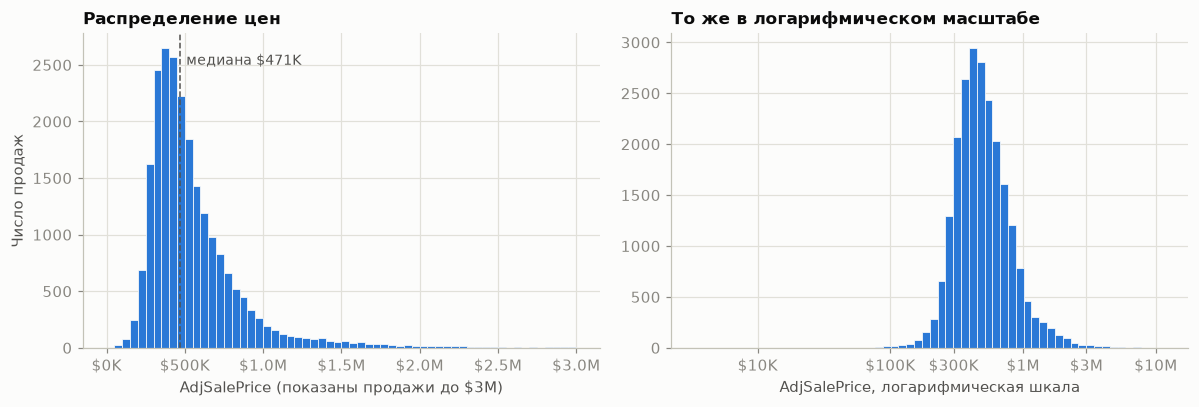

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(house["AdjSalePrice"], bins=np.arange(0, 3.05e6, 5e4), color=PAL["blue"],
         edgecolor=PAL["surface"], lw=0.5)
med = house["AdjSalePrice"].median()
ax1.axvline(med, color=PAL["ink2"], lw=1, ls="--")
ax1.text(med * 1.08, ax1.get_ylim()[1] * 0.9, f"медиана ${med / 1e3:,.0f}K", color=PAL["ink2"], fontsize=9)
ax1.xaxis.set_major_formatter(USD)
ax1.set_xlabel("AdjSalePrice (показаны продажи до $3M)")
ax1.set_ylabel("Число продаж")
ax1.set_title("Распределение цен")

ax2.hist(np.log10(house["AdjSalePrice"]), bins=60, color=PAL["blue"], edgecolor=PAL["surface"], lw=0.5)
ax2.set_xticks(np.log10([1e4, 1e5, 3e5, 1e6, 3e6, 1e7]), ["$10K", "$100K", "$300K", "$1M", "$3M", "$10M"])
ax2.set_xlabel("AdjSalePrice, логарифмическая шкала")
ax2.set_title("То же в логарифмическом масштабе")
fig.tight_layout()
save(fig, "01_price_distribution")

Распределение цен сильно скошено вправо: медиана $471K, среднее $565K, максимум $11.6M.
В логарифмическом масштабе распределение близко к симметричному. Из-за длинного правого
хвоста ошибки модели в долларах (RMSE) в основном определяются дорогими домами.

## 2. Простая линейная регрессия

Простая линейная регрессия описывает цену как линейную функцию одного признака:

AdjSalePrice = b₀ + b₁ · SqFtTotLiving + ошибка

Коэффициенты подбираются методом наименьших квадратов, то есть минимизируют сумму
квадратов остатков — разностей между фактической и предсказанной ценой.

In [5]:
simple_lm = LinearRegression()
simple_lm.fit(house[["SqFtTotLiving"]], house["AdjSalePrice"])
print_coefs(simple_lm.intercept_, ["SqFtTotLiving"], simple_lm.coef_)
simple_fitted = simple_lm.predict(house[["SqFtTotLiving"]])
print(f"R² = {r2_score(house['AdjSalePrice'], simple_fitted):.3f}")

Свободный член: -44,677
  SqFtTotLiving: 293.20
R² = 0.483


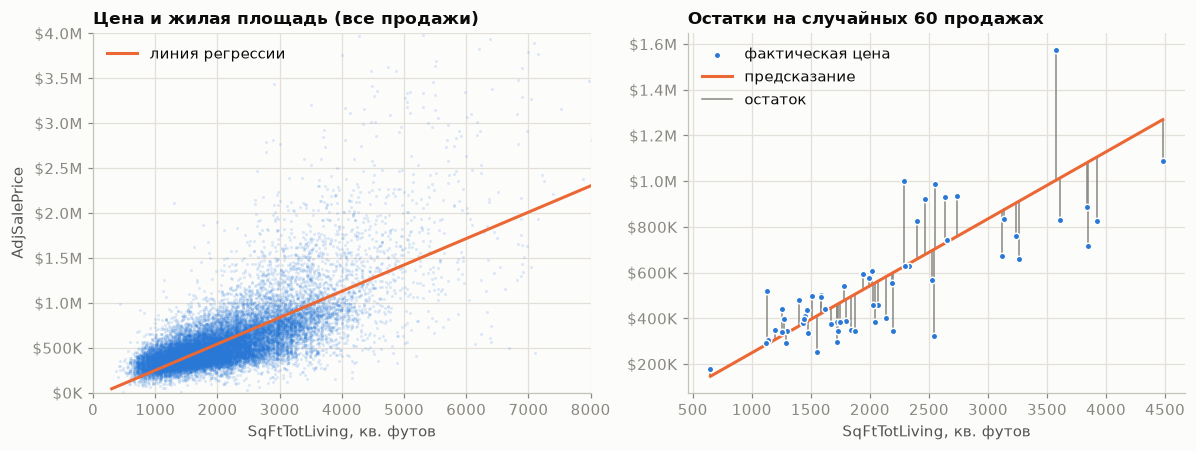

In [6]:
rng = np.random.default_rng(1)
sample = house.iloc[rng.choice(len(house), 60, replace=False)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.scatter(house["SqFtTotLiving"], house["AdjSalePrice"], s=4, alpha=0.15, color=PAL["blue"], lw=0)
xs = pd.DataFrame({"SqFtTotLiving": [300, 8000]})
ax1.plot(xs["SqFtTotLiving"], simple_lm.predict(xs), color=PAL["orange"], label="линия регрессии")
ax1.set_xlim(0, 8000)
ax1.set_ylim(0, 4e6)
ax1.yaxis.set_major_formatter(USD)
ax1.set_xlabel("SqFtTotLiving, кв. футов")
ax1.set_ylabel("AdjSalePrice")
ax1.set_title("Цена и жилая площадь (все продажи)")
ax1.legend(loc="upper left")

fitted_s = simple_lm.predict(sample[["SqFtTotLiving"]])
for x, y_act, y_fit in zip(sample["SqFtTotLiving"], sample["AdjSalePrice"], fitted_s):
    ax2.plot((x, x), (y_act, y_fit), color=PAL["muted"], lw=1)
ax2.scatter(sample["SqFtTotLiving"], sample["AdjSalePrice"], s=18, color=PAL["blue"], zorder=3,
            edgecolor=PAL["surface"], lw=1, label="фактическая цена")
xs2 = pd.DataFrame({"SqFtTotLiving": [sample["SqFtTotLiving"].min(), sample["SqFtTotLiving"].max()]})
ax2.plot(xs2["SqFtTotLiving"], simple_lm.predict(xs2), color=PAL["orange"], label="предсказание")
ax2.plot([], [], color=PAL["muted"], lw=1, label="остаток")
ax2.yaxis.set_major_formatter(USD)
ax2.set_xlabel("SqFtTotLiving, кв. футов")
ax2.set_title("Остатки на случайных 60 продажах")
ax2.legend(loc="upper left")
fig.tight_layout()
save(fig, "02_simple_regression")

Каждый квадратный фут жилой площади добавляет к цене в среднем $293. Одна площадь объясняет
48% дисперсии цены (R² = 0.48). Разброс цен вокруг линии растёт с площадью: у больших домов
ошибка предсказания заметно больше.

## 3. Множественная линейная регрессия

В модель добавляются площадь участка, число ванных и спален и класс качества постройки.
Каждый коэффициент показывает изменение цены при росте признака на единицу **при
неизменных остальных признаках**.

In [7]:
predictors = ["SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade"]
outcome = "AdjSalePrice"

house_lm = LinearRegression()
house_lm.fit(house[predictors], house[outcome])
print_coefs(house_lm.intercept_, predictors, house_lm.coef_)

Свободный член: -521,871
  SqFtTotLiving: 228.83
  SqFtLot: -0.06
  Bathrooms: -19,442.84
  Bedrooms: -47,769.96
  BldgGrade: 106,106.96


**Качество модели.** RMSE (корень из среднего квадрата ошибки) — типичная ошибка
предсказания в долларах. R² — доля дисперсии цены, объяснённая моделью.

In [8]:
fitted = house_lm.predict(house[predictors])
RMSE = np.sqrt(mean_squared_error(house[outcome], fitted))
r2 = r2_score(house[outcome], fitted)
print(f"RMSE: {RMSE:,.0f}")
print(f"R²:   {r2:.4f}")

RMSE: 261,220
R²:   0.5406


statsmodels дополнительно выдаёт стандартные ошибки коэффициентов, t-статистики,
p-значения и стандартную ошибку остатков (RSE). Свободный член добавляется явно
столбцом констант.

In [9]:
model = sm.OLS(house[outcome], house[predictors].assign(const=1))
results = model.fit()
print(results.summary())
print(f"\nRSE (стандартная ошибка остатков): {results.mse_resid ** 0.5:,.0f}")

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.541
Model:                            OLS   Adj. R-squared:                  0.540
Method:                 Least Squares   F-statistic:                     5338.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:15:53   Log-Likelihood:            -3.1517e+05
No. Observations:               22687   AIC:                         6.304e+05
Df Residuals:                   22681   BIC:                         6.304e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
SqFtTotLiving   228.8306      3.899     58.694

- **Жилая площадь:** +$229 за квадратный фут при неизменных остальных признаках, то есть
  +$229K за каждые 1000 кв. футов.
- **Класс постройки:** +$106K за каждую ступень `BldgGrade`.
- **Спальни и ванные** получили отрицательные коэффициенты (−$48K и −$19K). Это следствие
  корреляции признаков и неучтённого местоположения, разбирается в разделе 7.
- **Площадь участка** незначима (p = 0.32).
- Модель объясняет 54% дисперсии цены (R² = 0.54 против 0.48 у простой регрессии), RMSE —
  $261K. RSE практически совпадает с RMSE: при 22 тыс. наблюдений поправка на число
  параметров ничтожна.

## 4. Отбор признаков

### 4.1 Полная модель

В полную модель входят все характеристики дома. Категориальный `PropertyType`
кодируется фиктивными переменными, логический `NewConstruction` — нулём и единицей.

In [10]:
predictors_full = ["SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade",
                   "PropertyType", "NbrLivingUnits", "SqFtFinBasement", "YrBuilt",
                   "YrRenovated", "NewConstruction"]

X_full = pd.get_dummies(house[predictors_full], drop_first=True, dtype=int)
X_full["NewConstruction"] = X_full["NewConstruction"].astype(int)

house_full = sm.OLS(house[outcome], X_full.assign(const=1))
results_full = house_full.fit()
print(results_full.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.594
Method:                 Least Squares   F-statistic:                     2771.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:15:53   Log-Likelihood:            -3.1375e+05
No. Observations:               22687   AIC:                         6.275e+05
Df Residuals:                   22674   BIC:                         6.276e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
SqFtTotLiving       

### 4.2 Пошаговый отбор по AIC

Добавление признаков всегда уменьшает RMSE и увеличивает R² на обучающих данных, поэтому
для выбора модели используется критерий, штрафующий за сложность. **AIC** (информационный
критерий Акаике) для линейной регрессии:

AIC = n · ln(RSS / n) + 2 · P + const,

где n — число наблюдений, RSS — сумма квадратов остатков, P — число параметров.

Пошаговый отбор начинается с модели без признаков и на каждом шаге добавляет или убирает
один признак так, чтобы AIC уменьшился сильнее всего. Отбор останавливается, когда
ни одно действие не уменьшает AIC.

In [11]:
def aic_score(y_true, y_pred, n_params):
    """AIC линейной регрессии с нормальными ошибками; n_params — число коэффициентов."""
    n = len(y_true)
    rss = np.sum((np.asarray(y_true) - np.asarray(y_pred)) ** 2)
    return n * np.log(rss / n) + n * (1 + np.log(2 * np.pi)) + 2 * (n_params + 1)


def stepwise_selection(X, y, verbose=True):
    """Пошаговый отбор признаков (добавление и удаление) по AIC."""
    def fit_score(variables):
        if not variables:
            return None, aic_score(y, np.full(len(y), y.mean()), 1)
        m = LinearRegression().fit(X[variables], y)
        return m, aic_score(y, m.predict(X[variables]), len(variables) + 1)

    selected = []
    _, best_score = fit_score(selected)
    while True:
        candidates = [selected + [v] for v in X.columns if v not in selected]
        candidates += [[c for c in selected if c != v] for v in selected]
        scored = [(fit_score(c)[1], c) for c in candidates]
        score, variables = min(scored, key=lambda t: t[0])
        if score >= best_score:
            break
        if verbose:
            change = set(variables) ^ set(selected)
            action = "добавлен" if len(variables) > len(selected) else "удалён"
            print(f"{action} {change.pop():<28} AIC = {score:,.1f}")
        selected, best_score = variables, score
    return fit_score(selected)[0], selected


y = house[outcome]
best_model, best_variables = stepwise_selection(X_full, y)
print()
print_coefs(best_model.intercept_, best_variables, best_model.coef_)

добавлен SqFtTotLiving                AIC = 633,013.4
добавлен BldgGrade                    AIC = 630,793.7
добавлен YrBuilt                      AIC = 628,230.3
добавлен Bedrooms                     AIC = 627,784.2
добавлен Bathrooms                    AIC = 627,602.2
добавлен PropertyType_Townhouse       AIC = 627,525.7
добавлен SqFtFinBasement              AIC = 627,525.1
добавлен PropertyType_Single Family   AIC = 627,525.0



Свободный член: 6,178,645
  SqFtTotLiving: 199.28
  BldgGrade: 137,159.56
  YrBuilt: -3,565.42
  Bedrooms: -51,947.38
  Bathrooms: 42,396.16
  PropertyType_Townhouse: 84,479.16
  SqFtFinBasement: 7.05
  PropertyType_Single Family: 22,912.06


Пошаговый отбор оставил 8 признаков из 12 и исключил `SqFtLot`, `NbrLivingUnits`,
`YrRenovated` и `NewConstruction` — те же признаки, что незначимы в полной модели. Последние
два добавленных признака (`SqFtFinBasement` и `PropertyType_Single Family`) уменьшают AIC
меньше чем на единицу, то есть почти ничего не дают.

Коэффициент `YrBuilt` отрицателен: −$3.6K за каждый год. При той же площади и классе
постройки более старые дома дороже. Вероятная причина — местоположение: старые дома чаще
стоят в сложившихся районах ближе к центру, а признака местоположения в модели нет.

## 5. Взвешенная регрессия

Более старые продажи считаются менее надёжными, поэтому сделкам присваивается вес,
растущий со временем: число лет с 2005 года (2006 — вес 1, 2015 — вес 10).

In [12]:
house["Weight"] = house["Year"] - 2005

house_wt = LinearRegression()
house_wt.fit(house[predictors], house[outcome], sample_weight=house["Weight"])

coef_cmp = pd.DataFrame({
    "без весов": np.r_[house_lm.coef_, house_lm.intercept_],
    "с весами": np.r_[house_wt.coef_, house_wt.intercept_],
}, index=predictors + ["свободный член"])
coef_cmp

,без весов,с весами
SqFtTotLiving,228.831,245.024
SqFtLot,-0.060,-0.292
Bathrooms,"-19,442.840","-26,085.970"
Bedrooms,"-47,769.955","-53,608.876"
BldgGrade,"106,106.963","115,242.435"
свободный член,"-521,871.368","-584,189.329"


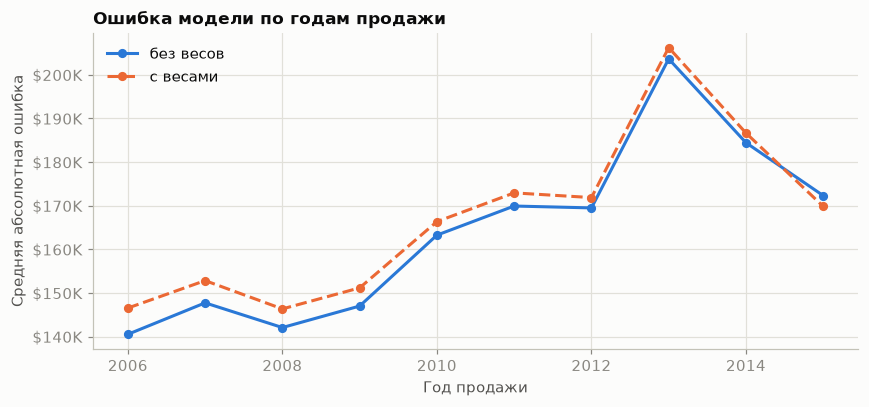

,без весов,с весами
Year,,
2006,"140,540.000","146,557.000"
2007,"147,748.000","152,849.000"
2008,"142,087.000","146,360.000"
2009,"147,017.000","151,183.000"
2010,"163,268.000","166,364.000"
2011,"169,937.000","172,951.000"
2012,"169,507.000","171,874.000"
2013,"203,660.000","206,242.000"
2014,"184,453.000","186,669.000"


In [13]:
abs_resid = pd.DataFrame({
    "Year": house["Year"],
    "без весов": np.abs(house_lm.predict(house[predictors]) - house[outcome]),
    "с весами": np.abs(house_wt.predict(house[predictors]) - house[outcome]),
})
mae_by_year = abs_resid.groupby("Year")[["без весов", "с весами"]].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
for col, color, ls in [("без весов", PAL["blue"], "-"), ("с весами", PAL["orange"], "--")]:
    ax.plot(mae_by_year.index, mae_by_year[col], color=color, ls=ls, marker="o", ms=5, label=col)
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Год продажи")
ax.set_ylabel("Средняя абсолютная ошибка")
ax.set_title("Ошибка модели по годам продажи")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "03_weighted_regression")
mae_by_year.round(0)

Веса немного сдвигают коэффициенты (цена квадратного фута $229 → $245, класс постройки
$106K → $115K), но средняя абсолютная ошибка взвешенной модели выше почти во всех годах;
ниже она только в 2015 году ($170K против $172K). Свежих продаж мало (156 в 2015 году),
поэтому перевзвешивание почти не улучшает модель для них, но ухудшает для основной массы
данных.

## 6. Категориальные признаки

### 6.1 Тип недвижимости

Категориальный признак с P уровнями кодируется P − 1 фиктивными переменными; первый
уровень (`Multiplex`) становится опорным, и коэффициенты остальных уровней показывают
разницу с ним. Все P столбцов вместе со свободным членом дали бы мультиколлинеарность.

In [14]:
print(pd.get_dummies(house["PropertyType"], dtype=int).head(6))
print(pd.get_dummies(house["PropertyType"], drop_first=True, dtype=int).head(6))

   Multiplex  Single Family  Townhouse
1          1              0          0
2          0              1          0
3          0              1          0
4          0              1          0
5          0              1          0
6          0              0          1
   Single Family  Townhouse
1              0          0
2              1          0
3              1          0
4              1          0
5              1          0
6              0          1


In [15]:
predictors_pt = ["SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade", "PropertyType"]
X_pt = pd.get_dummies(house[predictors_pt], drop_first=True, dtype=int)

house_lm_factor = LinearRegression()
house_lm_factor.fit(X_pt, house[outcome])
print_coefs(house_lm_factor.intercept_, X_pt.columns, house_lm_factor.coef_)

Свободный член: -446,841
  SqFtTotLiving: 223.37
  SqFtLot: -0.07
  Bathrooms: -15,979.01
  Bedrooms: -50,889.73
  BldgGrade: 109,416.31
  PropertyType_Single Family: -84,678.22
  PropertyType_Townhouse: -115,121.98


При прочих равных дома на одну семью оцениваются на $85K дешевле, а таунхаусы — на $115K
дешевле многоквартирных домов (`Multiplex`). Знак противоречит интуиции; в разделе 7.2 видно,
что это эффект неучтённого местоположения.

### 6.2 Почтовые индексы: признак с большим числом уровней

Почтовый индекс отражает местоположение — один из главных факторов цены, но у него
80 уровней, и по некоторым индексам всего несколько продаж. Индексы объединяются в пять
групп `ZipGroup` по медианному остатку базовой модели из раздела 3: индексы, где модель
сильнее всего занижает цену, попадают в группу 5, где завышает — в группу 1. Группы
формируются так, чтобы в каждую попало примерно равное число продаж.

In [16]:
print("Почтовых индексов:", house["ZipCode"].nunique())
print(house["ZipCode"].value_counts().describe().round(0).to_dict())


def make_zip_groups(zip_codes, residuals, n_groups=5):
    """Группы почтовых индексов по медианному остатку модели, равные по числу продаж."""
    zg = (pd.DataFrame({"ZipCode": zip_codes, "residual": residuals})
          .groupby("ZipCode")["residual"].agg(count="size", median_residual="median")
          .sort_values("median_residual"))
    zg["cum_count"] = zg["count"].cumsum()
    zg["ZipGroup"] = pd.qcut(zg["cum_count"], n_groups, labels=False) + 1
    return zg


zip_groups = make_zip_groups(house["ZipCode"], house[outcome] - house_lm.predict(house[predictors]))
house["ZipGroup"] = house["ZipCode"].map(zip_groups["ZipGroup"]).astype("category")

zip_summary = house.groupby("ZipGroup", observed=True).agg(
    индексов=("ZipCode", "nunique"), продаж=("ZipCode", "size"),
    медианная_цена=("AdjSalePrice", "median"))
zip_summary["медианный_остаток"] = (pd.Series(house[outcome] - house_lm.predict(house[predictors]))
                                    .groupby(house["ZipGroup"], observed=True).median())
zip_summary.round(0)

Почтовых индексов: 80
{'count': 80.0, 'mean': 284.0, 'std': 189.0, 'min': 1.0, '25%': 130.0, '50%': 288.0, '75%': 404.0, 'max': 788.0}


,индексов,продаж,медианная_цена,медианный_остаток
ZipGroup,,,,
1,16,4733,"368,592.000","-129,831.000"
2,16,3602,"483,966.000","-80,369.000"
3,16,4607,"450,621.000","-30,693.000"
4,16,4279,"442,540.000","26,202.000"
5,16,5466,"624,781.000","128,275.000"


## 7. Интерпретация уравнения регрессии

### 7.1 Коррелированные признаки

In [17]:
print_coefs(best_model.intercept_, best_variables, best_model.coef_)
print()
print(house[["SqFtTotLiving", "Bedrooms", "Bathrooms", "SqFtFinBasement"]].corr().round(2))

Свободный член: 6,178,645
  SqFtTotLiving: 199.28
  BldgGrade: 137,159.56
  YrBuilt: -3,565.42
  Bedrooms: -51,947.38
  Bathrooms: 42,396.16
  PropertyType_Townhouse: 84,479.16
  SqFtFinBasement: 7.05
  PropertyType_Single Family: 22,912.06

                 SqFtTotLiving  Bedrooms  Bathrooms  SqFtFinBasement
SqFtTotLiving            1.000     0.600      0.760            0.410
Bedrooms                 0.600     1.000      0.540            0.310
Bathrooms                0.760     0.540      1.000            0.270
SqFtFinBasement          0.410     0.310      0.270            1.000


In [18]:
predictors_red = ["Bedrooms", "BldgGrade", "PropertyType", "YrBuilt"]
X_red = pd.get_dummies(house[predictors_red], drop_first=True, dtype=int)

reduced_lm = LinearRegression()
reduced_lm.fit(X_red, house[outcome])
print_coefs(reduced_lm.intercept_, X_red.columns, reduced_lm.coef_)

Свободный член: 4,913,973
  Bedrooms: 27,150.54
  BldgGrade: 248,997.79
  YrBuilt: -3,211.74
  PropertyType_Single Family: -19,898.50
  PropertyType_Townhouse: -47,355.44


В модели пошагового отбора каждая дополнительная спальня снижает цену на $52K. Спальни
коррелируют с жилой площадью (r = 0.60) и числом ванных (r = 0.54), а площадь с ванными —
ещё сильнее (r = 0.76). Поэтому коэффициент описывает эффект спальни **при той же площади**:
больше спален при той же площади — меньше комнаты.

Если убрать из модели площади и ванные, коэффициент при спальнях становится положительным
(+$27K): теперь число спален само служит показателем размера дома.

### 7.2 Смешивающий фактор: местоположение

In [19]:
predictors_conf = ["SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade",
                   "PropertyType", "ZipGroup"]
X_conf = pd.get_dummies(house[predictors_conf], drop_first=True, dtype=int)

confounding_lm = LinearRegression()
confounding_lm.fit(X_conf, house[outcome])

conf_cmp = pd.DataFrame({
    "без ZipGroup": pd.Series(house_lm_factor.coef_, index=X_pt.columns),
    "с ZipGroup": pd.Series(confounding_lm.coef_, index=X_conf.columns),
})
conf_cmp.round(2)

,без ZipGroup,с ZipGroup
Bathrooms,"-15,979.010","5,928.430"
Bedrooms,"-50,889.730","-41,682.870"
BldgGrade,"109,416.310","98,541.180"
PropertyType_Single Family,"-84,678.220","19,323.630"
PropertyType_Townhouse,"-115,121.980","-78,198.720"
SqFtLot,-0.070,0.450
SqFtTotLiving,223.370,210.610
ZipGroup_2,NaN,"53,317.170"
ZipGroup_3,NaN,"116,251.590"
ZipGroup_4,NaN,"178,360.530"


Местоположение — смешивающий фактор: оно связано и с ценой, и с характеристиками дома.
После добавления `ZipGroup`:
- коэффициенты площади участка и числа ванных меняют знак на положительный (−$0.07 → +$0.45
  за кв. фут участка, −$16K → +$6K за ванную);
- дома на одну семью становятся дороже многоквартирных (−$85K → +$19K);
- дом в самой дорогой группе индексов стоит на $338K больше, чем в самой дешёвой.

Коэффициент при спальнях остаётся отрицательным (−$42K) по той же причине, что и выше.

### 7.3 Взаимодействия

Без взаимодействий модель предполагает, что каждый квадратный фут добавляет к цене
одинаковую сумму в любом районе. Член `SqFtTotLiving * ZipGroup` позволяет цене
квадратного фута зависеть от группы почтовых индексов.

In [20]:
model_int = smf.ols(formula="AdjSalePrice ~ SqFtTotLiving*ZipGroup + SqFtLot + "
                            "Bathrooms + Bedrooms + BldgGrade + PropertyType", data=house)
results_int = model_int.fit()
print(results_int.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.682
Method:                 Least Squares   F-statistic:                     3247.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:15:53   Log-Likelihood:            -3.1098e+05
No. Observations:               22687   AIC:                         6.220e+05
Df Residuals:                   22671   BIC:                         6.221e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

ZipGroup
1   115.000
2   147.000
3   157.000
4   184.000
5   341.000


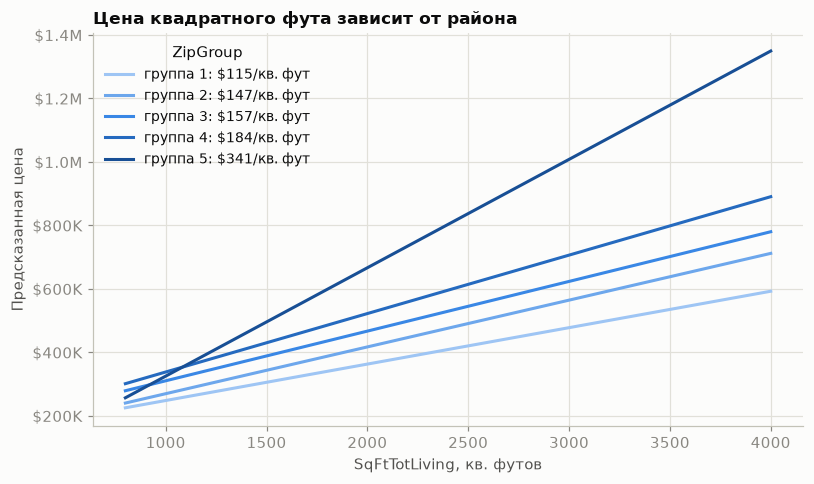

In [21]:
base_slope = results_int.params["SqFtTotLiving"]
slopes = pd.Series({1: base_slope} | {
    g: base_slope + results_int.params[f"SqFtTotLiving:ZipGroup[T.{g}]"] for g in range(2, 6)},
    name="$ за кв. фут")
slopes.index.name = "ZipGroup"
print(slopes.round(0).to_string())

typical = {"SqFtLot": house["SqFtLot"].median(), "Bathrooms": 2.0, "Bedrooms": 3,
           "BldgGrade": 7, "PropertyType": "Single Family"}
sqft = np.linspace(800, 4000, 50)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for g, color in zip(range(1, 6), BLUE_RAMP):
    grid = pd.DataFrame({"SqFtTotLiving": sqft, "ZipGroup": g, **typical})
    grid["ZipGroup"] = pd.Categorical(grid["ZipGroup"], categories=house["ZipGroup"].cat.categories)
    ax.plot(sqft, results_int.predict(grid), color=color, label=f"группа {g}: ${slopes[g]:,.0f}/кв. фут")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("SqFtTotLiving, кв. футов")
ax.set_ylabel("Предсказанная цена")
ax.set_title("Цена квадратного фута зависит от района")
ax.legend(title="ZipGroup", loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "04_interaction")

Цена квадратного фута сильно зависит от района: $115 в группе 1 и $341 в группе 5, то есть
в 3 раза больше. Модель со взаимодействием объясняет 68% дисперсии цены против 54%
у базовой модели. При площади меньше ~1000 кв. футов линия группы 5 оказывается ниже
остальных: таких домов в дорогих районах мало, и модель там экстраполирует.

## 8. Диагностика регрессии

Диагностика выполняется на продажах в одном почтовом индексе, 98105: на небольшой выборке
отдельные наблюдения заметнее влияют на модель.

### 8.1 Выбросы

In [22]:
house_98105 = house.loc[house["ZipCode"] == 98105].copy()
print("Продаж в индексе 98105:", len(house_98105))

house_outlier = sm.OLS(house_98105[outcome], house_98105[predictors].assign(const=1))
result_98105 = house_outlier.fit()
print(result_98105.summary())

Продаж в индексе 98105: 313


                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.792
Method:                 Least Squares   F-statistic:                     238.7
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          1.69e-103
Time:                        22:15:53   Log-Likelihood:                -4226.0
No. Observations:                 313   AIC:                             8464.
Df Residuals:                     307   BIC:                             8486.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
SqFtTotLiving   209.6023     24.408      8.587

Выброс в регрессии — наблюдение, фактическое значение которого далеко от предсказанного.
Для поиска используются стандартизированные (стьюдентизированные) остатки: остаток,
делённый на его стандартную ошибку.

In [23]:
influence = OLSInfluence(result_98105)
sresiduals = influence.resid_studentized_internal
print(f"Минимальный стандартизированный остаток: {sresiduals.min():.2f} (строка {sresiduals.idxmin()})")
print(f"Остаток в долларах: {result_98105.resid.loc[sresiduals.idxmin()]:,.0f}")

outlier = house_98105.loc[sresiduals.idxmin()]
outlier[[outcome] + predictors]

Минимальный стандартизированный остаток: -4.33 (строка 24333)
Остаток в долларах: -757,754


AdjSalePrice    119,748.000
SqFtTotLiving          2900
SqFtLot                7276
Bathrooms             3.000
Bedrooms                  6
BldgGrade                 7
Name: 24333, dtype: object

Самый большой отрицательный остаток — 4.3 стандартной ошибки: модель предсказала цену на
$758K выше фактической. Дом площадью 2900 кв. футов с тремя ванными продан за $120K, что
для этого индекса нетипично. Вероятно, это не обычная рыночная сделка (например, продажа доли
в собственности) или ошибка в данных. Для задач поиска аномалий такие записи и являются
целью анализа.

### 8.2 Влиятельные наблюдения

Влиятельное наблюдение заметно меняет уравнение регрессии, даже если его остаток невелик.
- **Плечо (hat-значение)** показывает, насколько необычны значения признаков наблюдения;
  высоким считается значение больше 2(P + 1)/n.
- **Расстояние Кука** объединяет плечо и величину остатка; высоким считается значение
  больше 4/(n − P − 1).

Порог плеча 2(P+1)/n = 0.038; наблюдений выше порога: 19
Порог Кука 4/(n−P−1) = 0.013; наблюдений выше порога: 20


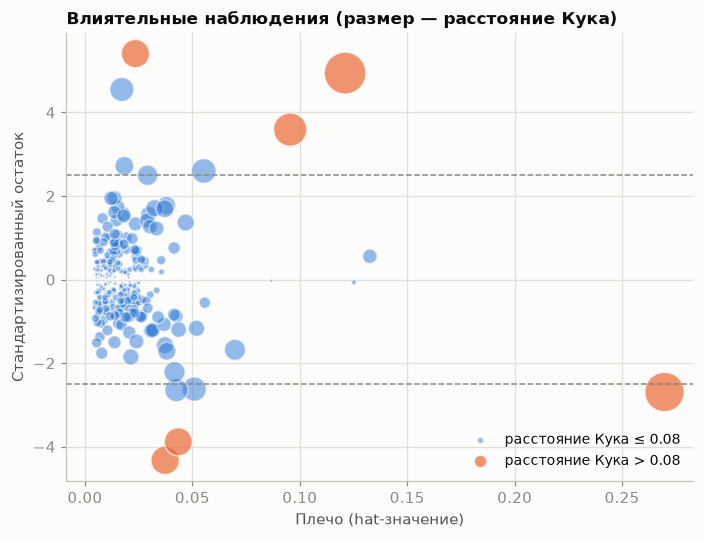

In [24]:
cooks = influence.cooks_distance[0]
n_obs, n_pred = len(house_98105), len(predictors)
print(f"Порог плеча 2(P+1)/n = {2 * (n_pred + 1) / n_obs:.3f}; "
      f"наблюдений выше порога: {(influence.hat_matrix_diag > 2 * (n_pred + 1) / n_obs).sum()}")
print(f"Порог Кука 4/(n−P−1) = {4 / (n_obs - n_pred - 1):.3f}; "
      f"наблюдений выше порога: {(cooks > 4 / (n_obs - n_pred - 1)).sum()}")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axhline(-2.5, ls="--", color=PAL["muted"], lw=1)
ax.axhline(2.5, ls="--", color=PAL["muted"], lw=1)
big = cooks > 0.08
ax.scatter(influence.hat_matrix_diag[~big], sresiduals[~big], s=1000 * np.sqrt(cooks[~big]),
           color=PAL["blue"], alpha=0.5, edgecolor=PAL["surface"], lw=1, label="расстояние Кука ≤ 0.08")
ax.scatter(influence.hat_matrix_diag[big], sresiduals[big], s=1000 * np.sqrt(cooks[big]),
           color=PAL["orange"], alpha=0.7, edgecolor=PAL["surface"], lw=1, label="расстояние Кука > 0.08")
ax.set_xlabel("Плечо (hat-значение)")
ax.set_ylabel("Стандартизированный остаток")
ax.set_title("Влиятельные наблюдения (размер — расстояние Кука)")
ax.legend(loc="lower right", fontsize=9, markerscale=0.35)
fig.tight_layout()
save(fig, "05_influence")

In [25]:
house_infl = house_98105.loc[cooks < 0.08]
result_infl = sm.OLS(house_infl[outcome], house_infl[predictors].assign(const=1)).fit()
print("Удалено наблюдений:", len(house_98105) - len(house_infl))
pd.DataFrame({"все данные": result_98105.params, "без влиятельных": result_infl.params}).round(0)

Удалено наблюдений: 6


,все данные,без влиятельных
SqFtTotLiving,210.000,230.000
SqFtLot,39.000,33.000
Bathrooms,"2,282.000","-16,132.000"
Bedrooms,"-26,320.000","-22,888.000"
BldgGrade,"130,000.000","114,871.000"
const,"-772,550.000","-647,137.000"


Порог по плечу превышают 19 наблюдений из 313, порог Кука — 20. Удаление 6 самых влиятельных
наблюдений (расстояние Кука > 0.08) заметно меняет модель: коэффициент при ванных меняется
с +$2K на −$16K, класс постройки — со $130K на $115K. На небольшой выборке несколько
наблюдений могут существенно сдвинуть коэффициенты; на 22 тыс. продаж этот эффект размывается.

### 8.3 Гетероскедастичность и распределение остатков

Гетероскедастичность — непостоянство разброса остатков в разных диапазонах предсказаний.
Она указывает, что модель хуже описывает часть домов, и делает формульные интервалы
предсказания неточными.

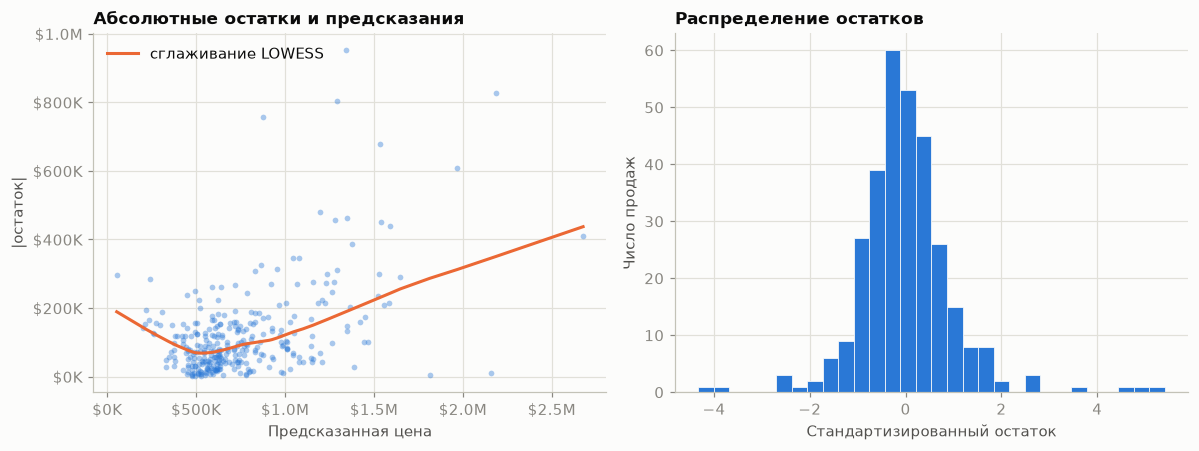

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
fv, ar = result_98105.fittedvalues, np.abs(result_98105.resid)
smooth = sm.nonparametric.lowess(ar, fv, frac=2 / 3)
ax1.scatter(fv, ar, s=14, alpha=0.4, color=PAL["blue"], lw=0)
ax1.plot(smooth[:, 0], smooth[:, 1], color=PAL["orange"], label="сглаживание LOWESS")
ax1.xaxis.set_major_formatter(USD)
ax1.yaxis.set_major_formatter(USD)
ax1.set_xlabel("Предсказанная цена")
ax1.set_ylabel("|остаток|")
ax1.set_title("Абсолютные остатки и предсказания")
ax1.legend(loc="upper left")

ax2.hist(sresiduals, bins=30, color=PAL["blue"], edgecolor=PAL["surface"], lw=0.5)
ax2.set_xlabel("Стандартизированный остаток")
ax2.set_ylabel("Число продаж")
ax2.set_title("Распределение остатков")
fig.tight_layout()
save(fig, "06_heteroskedasticity")

Остатки гетероскедастичны: средний абсолютный остаток растёт примерно с $70K при
предсказанной цене $500K до ~$440K при $2.5M и повышен у самых дешёвых предсказаний.
Распределение стандартизированных остатков имеет тяжёлые хвосты (значения до −4 и +5).
Модель хуже всего описывает дорогие дома — вероятно, ей не хватает признаков, важных именно
для этого сегмента.

### 8.4 Частные остатки

Частный остаток признака — остаток модели плюс вклад этого признака bᵢ·Xᵢ. График частных
остатков показывает, насколько хорошо линейный член описывает связь признака с ценой
с учётом остальных признаков.

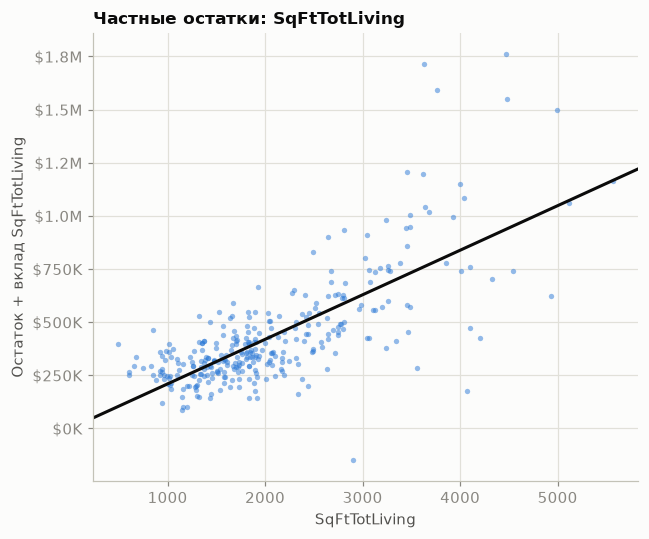

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))
sm.graphics.plot_ccpr(result_98105, "SqFtTotLiving", ax=ax)
style_points(ax)
ax.set_title("Частные остатки: SqFtTotLiving")
ax.set_ylabel("Остаток + вклад SqFtTotLiving")
ax.yaxis.set_major_formatter(USD)
fig.tight_layout()
save(fig, "07_partial_residuals_linear")

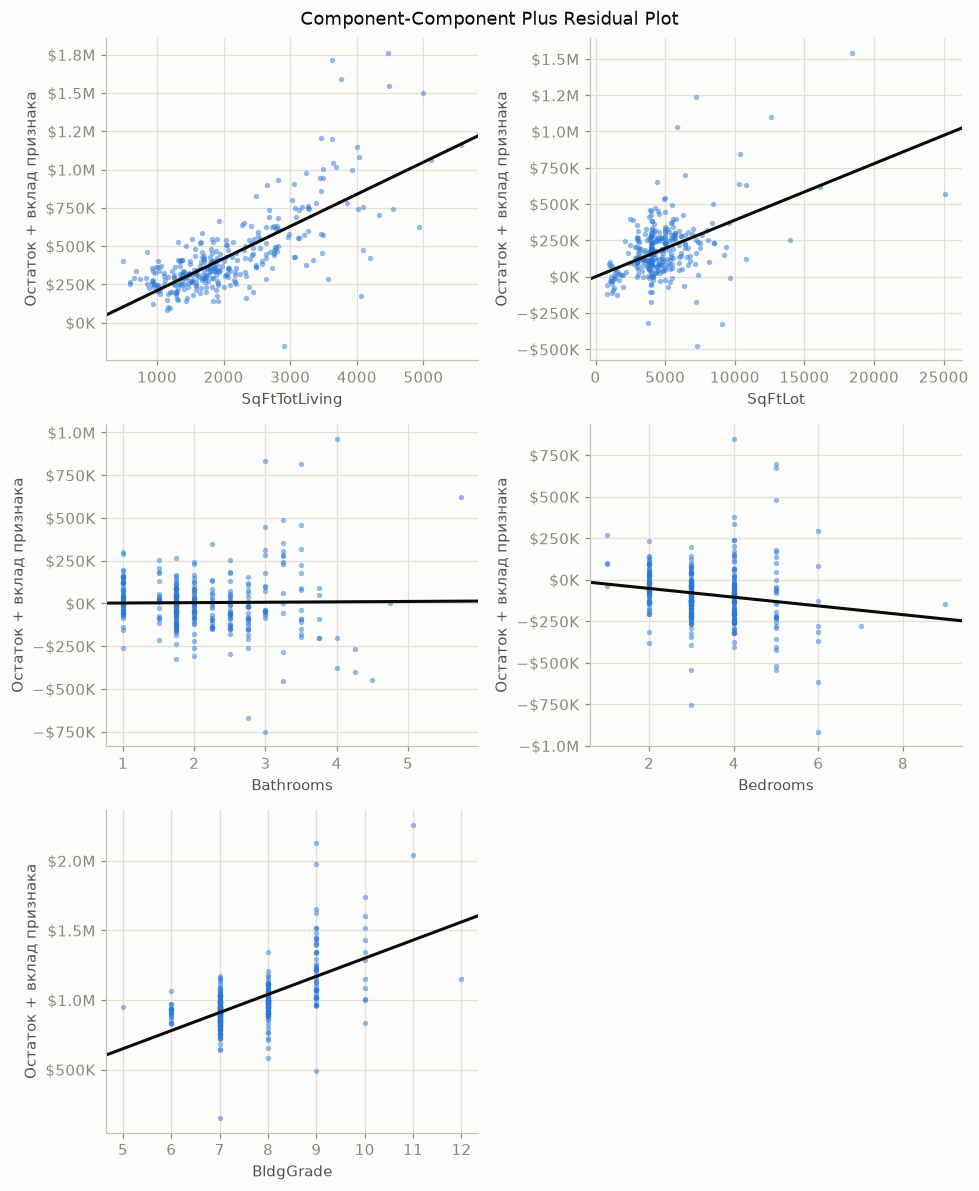

In [28]:
fig = plt.figure(figsize=(9, 11))
sm.graphics.plot_ccpr_grid(result_98105, fig=fig)
for ax in fig.axes:
    style_points(ax)
    ax.set_ylabel("Остаток + вклад признака")
    ax.yaxis.set_major_formatter(USD)
fig.tight_layout()
plt.show()

Линейный член плохо описывает жилую площадь: для домов меньше ~1000 кв. футов частные
остатки лежат в основном выше прямой (модель занижает цену), а в диапазоне 2000–3000 кв.
футов — ниже (завышает). Связь площади с ценой нелинейна; выше 4000 кв. футов данных
слишком мало для выводов.

## 9. Нелинейность

### 9.1 Полиномиальная регрессия

Квадратичный член `SqFtTotLiving²` позволяет цене квадратного фута меняться с площадью.

In [29]:
model_poly = smf.ols(formula="AdjSalePrice ~ SqFtTotLiving + np.power(SqFtTotLiving, 2) + "
                             "SqFtLot + Bathrooms + Bedrooms + BldgGrade", data=house_98105)
result_poly = model_poly.fit()
print(result_poly.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.802
Method:                 Least Squares   F-statistic:                     211.6
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          9.95e-106
Time:                        22:15:54   Log-Likelihood:                -4217.9
No. Observations:                 313   AIC:                             8450.
Df Residuals:                     306   BIC:                             8476.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

Встроенный график частных остатков statsmodels работает только с линейными членами,
поэтому для полинома и сплайнов используется собственная функция: вклад признака
считается как предсказание модели, в которой остальные признаки обнулены.

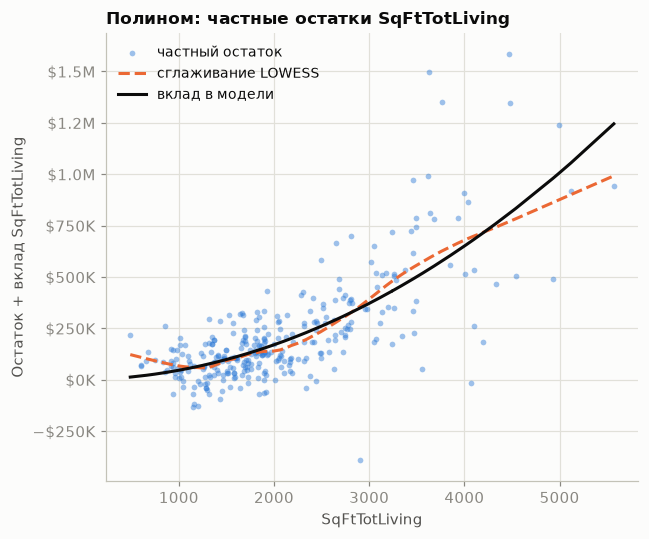

Коэффициент при SqFtTotLiving²: 0.0388


In [30]:
def partial_residual_plot(model, df, outcome, feature, ax):
    y_pred = model.predict(df)
    required = set(model.params.index).intersection(df.columns)
    required.add(feature)
    copy_df = df[list(required)].copy().astype("float")
    for c in copy_df.columns:
        if c != feature:
            copy_df[c] = 0.0
    feature_prediction = model.predict(copy_df)
    results_pr = pd.DataFrame({
        "feature": df[feature],
        "residual": df[outcome] - y_pred,
        "ypartial": feature_prediction - model.params.iloc[0],
    }).sort_values("feature")
    smoothed = sm.nonparametric.lowess(results_pr.ypartial + results_pr.residual,
                                       results_pr.feature, frac=1 / 3)
    ax.scatter(results_pr.feature, results_pr.ypartial + results_pr.residual, s=14,
               alpha=0.45, color=PAL["blue"], lw=0, label="частный остаток")
    ax.plot(smoothed[:, 0], smoothed[:, 1], color=PAL["orange"], ls="--", label="сглаживание LOWESS")
    ax.plot(results_pr.feature, results_pr.ypartial, color=PAL["ink"], label="вклад в модели")
    ax.set_xlabel(feature)
    ax.set_ylabel(f"Остаток + вклад {feature}")
    ax.yaxis.set_major_formatter(USD)
    return ax


fig, ax = plt.subplots(figsize=(6, 5))
partial_residual_plot(result_poly, house_98105, outcome, "SqFtTotLiving", ax)
ax.set_title("Полином: частные остатки SqFtTotLiving")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "08_partial_residuals_poly")
print(f"Коэффициент при SqFtTotLiving²: {result_poly.params.iloc[2]:.4f}")

### 9.2 Сплайны

B-сплайн (`bs`) — кусочный кубический многочлен, гладко склеенный в узлах. При `df=6`
и степени 3 у сплайна 3 внутренних узла.

In [31]:
formula_spline = ("AdjSalePrice ~ bs(SqFtTotLiving, df=6, degree=3) + "
                  "SqFtLot + Bathrooms + Bedrooms + BldgGrade")
result_spline = smf.ols(formula=formula_spline, data=house_98105).fit()
print(result_spline.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     131.8
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          7.10e-104
Time:                        22:15:54   Log-Likelihood:                -4211.4
No. Observations:                 313   AIC:                             8445.
Df Residuals:                     302   BIC:                             8486.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


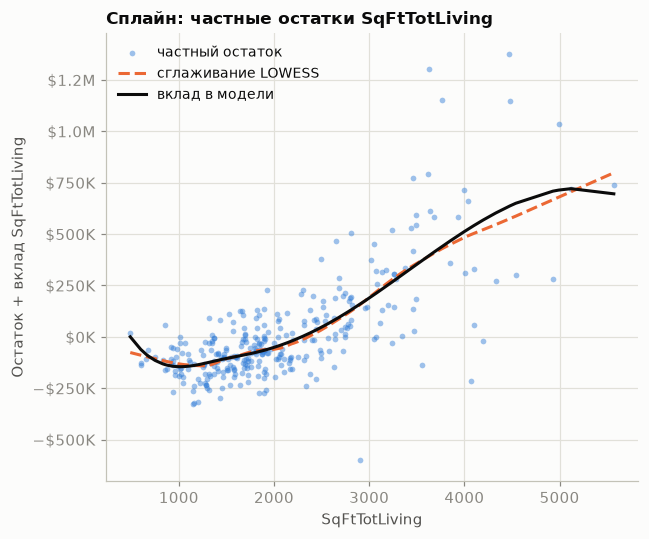

In [32]:
fig, ax = plt.subplots(figsize=(6, 5))
partial_residual_plot(result_spline, house_98105, outcome, "SqFtTotLiving", ax)
ax.set_title("Сплайн: частные остатки SqFtTotLiving")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "09_partial_residuals_spline")

### 9.3 Обобщённая аддитивная модель (GAM)

В сплайновой регрессии число и положение узлов задаются вручную. GAM представляет каждый
признак гладкой функцией и подбирает её гибкость автоматически.

**statsmodels.** `GLMGam` с B-сплайнами: 10 степеней свободы для жилой площади, по 3 для
остальных признаков; штраф за изогнутость (`alpha`) равен нулю. Формула содержит только
свободный член: все эффекты признаков задаются сплайнами, а отдельные линейные члены
дублировали бы их и делали бы матрицу признаков вырожденной.

In [33]:
predictors_gam = ["SqFtTotLiving", "SqFtLot", "Bathrooms", "Bedrooms", "BldgGrade"]
x_spline = house_98105[predictors_gam]
bse = BSplines(x_spline, df=[10] + [3] * 4, degree=[3] + [2] * 4)
alpha = np.array([0] * 5)

gam_sm = GLMGam.from_formula("AdjSalePrice ~ 1", data=house_98105, smoother=bse, alpha=alpha)
res_sm = gam_sm.fit()
print(res_sm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           AdjSalePrice   No. Observations:                  313
Model:                         GLMGam   Df Residuals:                   295.00
Model Family:                Gaussian   Df Model:                        17.00
Link Function:               Identity   Scale:                      2.7471e+10
Method:                         PIRLS   Log-Likelihood:                -4196.6
Date:                Fri, 06 Nov 2026   Deviance:                   8.1039e+12
Time:                        22:15:55   Pearson chi2:                 8.10e+12
No. Iterations:                     3   Pseudo R-squ. (CS):             0.9901
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         2.427e+05   1.32e+05  

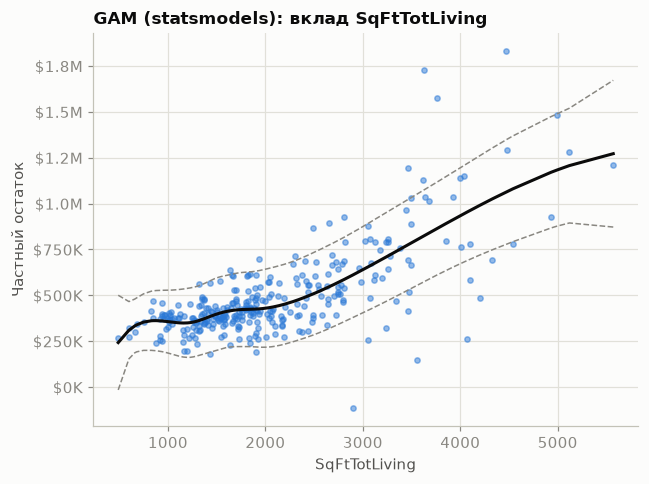

In [34]:
fig = res_sm.plot_partial(0, cpr=True)
ax = fig.axes[0]
for i, line in enumerate(ax.lines):  # 0 — оценка вклада, 1 и 2 — границы доверительного интервала
    line.set(color=PAL["ink"] if i == 0 else PAL["muted"], linewidth=2 if i == 0 else 1,
             linestyle="-" if i == 0 else "--")
ax.collections[0].set(color=PAL["blue"], alpha=0.5, sizes=[12])
ax.set_ylabel("Частный остаток")
ax.set_title("GAM (statsmodels): вклад SqFtTotLiving")
ax.yaxis.set_major_formatter(USD)
fig.set_size_inches(6, 4.5)
fig.tight_layout()
save(fig, "10_gam_statsmodels")

**pyGAM.** `LinearGAM` — GAM для непрерывного отклика (нормальное распределение,
тождественная связь): гладкий член `s()` с 12 сплайнами для жилой площади и линейные
члены `l()` для остальных признаков. Штраф λ подбирается перебором `gridsearch`.

In [35]:
X_gam = house_98105[predictors_gam].values  # s() и l() принимают номер столбца
y_gam = house_98105[outcome]

gam = LinearGAM(s(0, n_splines=12) + l(1) + l(2) + l(3) + l(4))
gam.gridsearch(X_gam, y_gam, progress=False)
gam.summary()

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                      7.6772
Link Function:                     IdentityLink Log Likelihood:                                 -4213.0332
Number of Samples:                          313 AIC:                                             8443.4209
                                                AICc:                                            8443.9746
                                                GCV:                                      30838885095.1688
                                                Scale:                                         171698.5198
                                                Pseudo R-Squared:                                   0.8117
Feature Function                  Lam

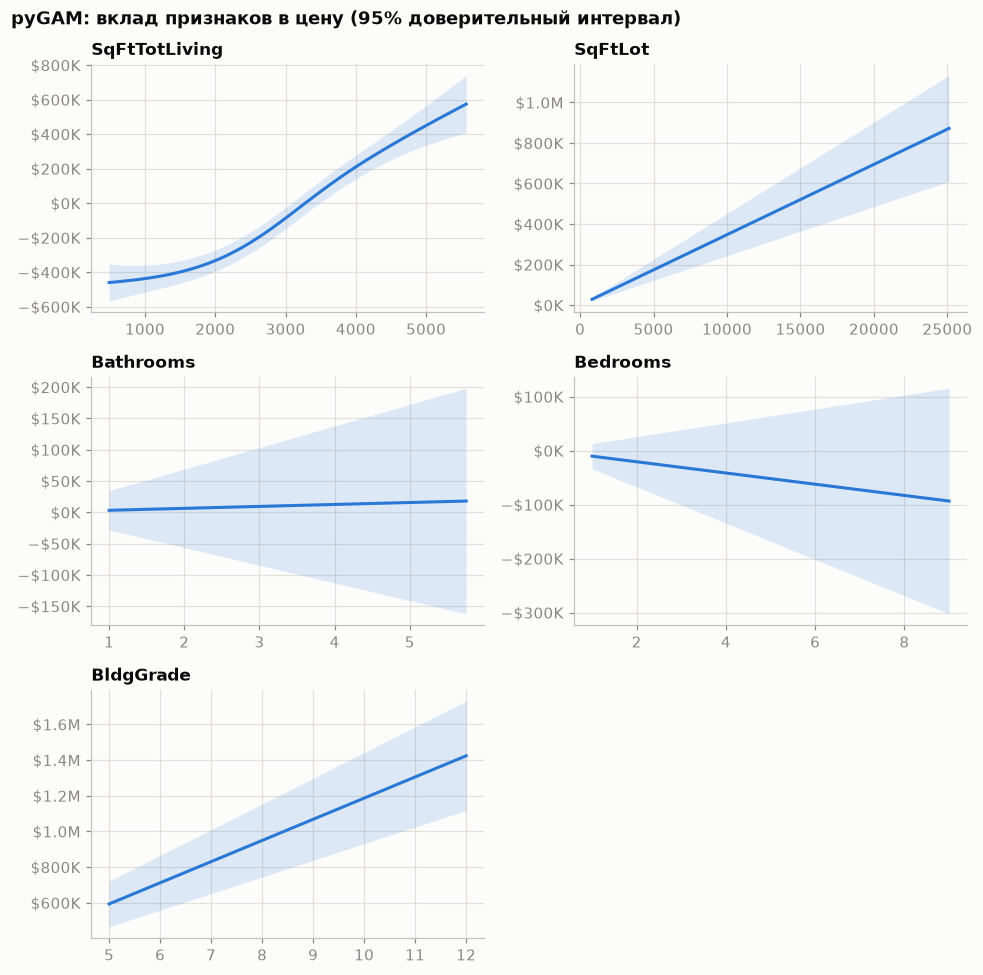

In [36]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(9, 9))
for i, title in enumerate(predictors_gam):
    ax = axes[i // 2, i % 2]
    XX = gam.generate_X_grid(term=i)
    pdep, conf = gam.partial_dependence(term=i, X=XX, width=0.95)
    ax.fill_between(XX[:, i], conf[:, 0], conf[:, 1], color=PAL["blue"], alpha=0.15, lw=0)
    ax.plot(XX[:, i], pdep, color=PAL["blue"])
    ax.yaxis.set_major_formatter(USD)
    ax.set_title(title)
axes[2][1].set_visible(False)
fig.suptitle("pyGAM: вклад признаков в цену (95% доверительный интервал)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save(fig, "11_gam_pygam")

| Модель (индекс 98105, 313 продаж) | R² | AIC |
|---|---|---|
| Линейная | 0.795 | 8464 |
| Квадратичный член по площади | 0.806 | 8450 |
| B-сплайн по площади (`df=6`) | 0.814 | 8445 |
| GAM (pyGAM, 7.7 эффективных степеней свободы) | 0.812 | 8443 |

- Коэффициент при `SqFtTotLiving²` положителен: на этих данных цена квадратного фута
  растёт с площадью дома.
- Сплайн и GAM показывают одинаковую форму: до ~1200 кв. футов кривая почти плоская, затем
  круто растёт до ~4000 кв. футов и выполаживается выше 5000, где данных мало.
- В pyGAM вклад остальных признаков линейный; у ванных и спален доверительные интервалы
  включают ноль. Вертикальный уровень кривых произволен, значение имеет их наклон и форма.
- Все нелинейные модели лучше линейной по AIC, но выигрыш умеренный.

## 10. Регуляризация: Lasso

Lasso добавляет к сумме квадратов остатков штраф α·Σ|bⱼ|. С ростом α коэффициенты
сжимаются, а часть из них становится ровно нулём, то есть Lasso одновременно отбирает
признаки. Признаки предварительно стандартизируются, иначе штраф зависел бы от единиц
измерения. Значение α подбирается 5-кратной кросс-валидацией (`LassoCV`).

Лучшее α по кросс-валидации: 1,125


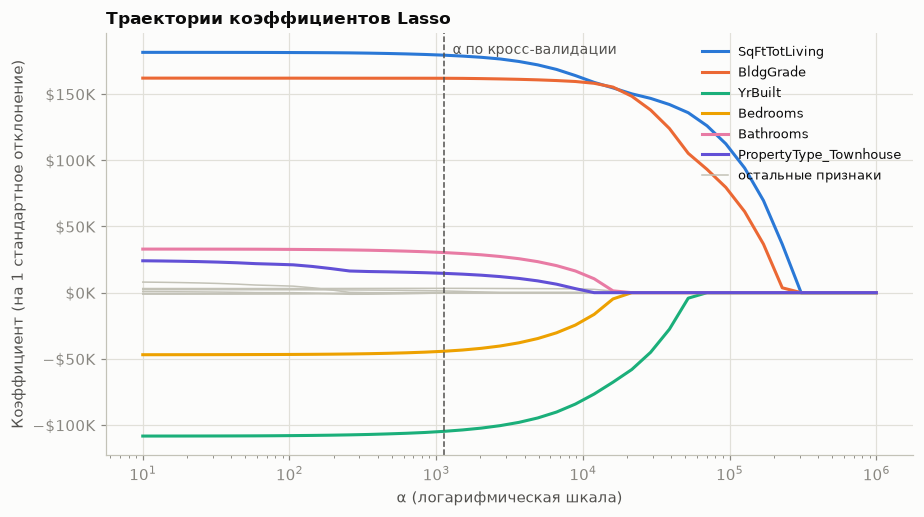

,коэффициент
SqFtTotLiving,"179,363.000"
SqFtLot,"1,301.000"
Bathrooms,"30,280.000"
Bedrooms,"-44,276.000"
BldgGrade,"161,914.000"
NbrLivingUnits,-214.000
SqFtFinBasement,"3,250.000"
YrBuilt,"-104,766.000"
YrRenovated,-0.000
NewConstruction,-0.000


In [37]:
X_lasso = X_full.copy()
columns = X_lasso.columns
X_std = StandardScaler().fit_transform(X_lasso)

alpha_values = np.logspace(1, 6, 40)
paths = pd.DataFrame([Lasso(alpha=a, max_iter=50_000).fit(X_std, y).coef_ for a in alpha_values],
                     index=alpha_values, columns=columns)
lasso_cv = LassoCV(cv=5, alphas=alpha_values, max_iter=50_000).fit(X_std, y)
print(f"Лучшее α по кросс-валидации: {lasso_cv.alpha_:,.0f}")

top = paths.iloc[0].abs().sort_values(ascending=False).index[:6]
colors = [PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"], PAL["magenta"], PAL["violet"]]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for c in columns:
    if c not in top:
        ax.plot(paths.index, paths[c], color=PAL["axis"], lw=1)
for c, color in zip(top, colors):
    ax.plot(paths.index, paths[c], color=color, label=c)
ax.plot([], [], color=PAL["axis"], lw=1, label="остальные признаки")
ax.axvline(lasso_cv.alpha_, color=PAL["ink2"], lw=1, ls="--")
ax.text(lasso_cv.alpha_ * 1.15, ax.get_ylim()[1] * 0.92, "α по кросс-валидации", fontsize=9, color=PAL["ink2"])
ax.set_xscale("log")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("α (логарифмическая шкала)")
ax.set_ylabel("Коэффициент (на 1 стандартное отклонение)")
ax.set_title("Траектории коэффициентов Lasso")
ax.legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
save(fig, "12_lasso_paths")

pd.DataFrame({"коэффициент": lasso_cv.coef_}, index=columns).round(0)

Кросс-валидация выбрала небольшой штраф (α ≈ 1100), поэтому коэффициенты почти не сжаты,
а Lasso обнулил `YrRenovated`, `NewConstruction` и `PropertyType_Single Family`. По
траекториям видна важность признаков: последними обнуляются жилая площадь и класс
постройки, затем год постройки. Коэффициенты здесь отражают изменение цены при росте
признака на одно стандартное отклонение: +$179K для жилой площади, +$162K для класса
постройки, −$105K для года постройки.

## 11. Сравнение моделей на отложенной выборке

Все метрики выше посчитаны на тех же данных, на которых модели обучались. Для честного
сравнения данные делятся на обучающую (75%) и тестовую (25%) части; модели обучаются на
обучающей части, качество измеряется на тестовой.

`ZipGroup` пересчитывается по остаткам базовой модели **только на обучающей части**:
группы, построенные по всем данным, содержали бы информацию о ценах тестовых домов.
Почтовые индексы, которых нет в обучающей части, относятся к средней группе (3).

Пошаговый отбор признаков тоже повторяется на обучающей части.

In [38]:
train, test = train_test_split(house, test_size=0.25, random_state=42)
train, test = train.copy(), test.copy()

base_train = LinearRegression().fit(train[predictors], train[outcome])
zg_train = make_zip_groups(train["ZipCode"], train[outcome] - base_train.predict(train[predictors]))
for part in (train, test):
    part["ZipGroup"] = pd.Categorical(part["ZipCode"].map(zg_train["ZipGroup"]).fillna(3).astype(int),
                                      categories=[1, 2, 3, 4, 5])
print("Тестовых продаж с новым почтовым индексом:", (~test["ZipCode"].isin(zg_train.index)).sum())

X_full_train = pd.get_dummies(train[predictors_full], drop_first=True, dtype=int)
X_full_train["NewConstruction"] = X_full_train["NewConstruction"].astype(int)
X_full_test = pd.get_dummies(test[predictors_full], drop_first=True, dtype=int)
X_full_test["NewConstruction"] = X_full_test["NewConstruction"].astype(int)
X_full_test = X_full_test.reindex(columns=X_full_train.columns, fill_value=0)

_, step_vars_train = stepwise_selection(X_full_train, train[outcome], verbose=False)
print("Пошаговый отбор на обучающей части:", step_vars_train)

Тестовых продаж с новым почтовым индексом: 1
Пошаговый отбор на обучающей части: ['SqFtTotLiving', 'BldgGrade', 'YrBuilt', 'Bedrooms', 'Bathrooms', 'PropertyType_Townhouse', 'PropertyType_Single Family']


In [39]:
def evaluate(name, pred_test, pred_train):
    return {"модель": name,
            "RMSE (train)": np.sqrt(mean_squared_error(train[outcome], pred_train)),
            "RMSE (test)": np.sqrt(mean_squared_error(test[outcome], pred_test)),
            "MAE (test)": mean_absolute_error(test[outcome], pred_test),
            "R² (test)": r2_score(test[outcome], pred_test)}


rows = []

m = LinearRegression().fit(train[["SqFtTotLiving"]], train[outcome])
rows.append(evaluate("1. Простая: SqFtTotLiving", m.predict(test[["SqFtTotLiving"]]),
                     m.predict(train[["SqFtTotLiving"]])))

rows.append(evaluate("2. Базовая: 5 признаков", base_train.predict(test[predictors]),
                     base_train.predict(train[predictors])))

m = LinearRegression().fit(X_full_train[step_vars_train], train[outcome])
rows.append(evaluate(f"3. Пошаговый отбор: {len(step_vars_train)} признаков",
                     m.predict(X_full_test[step_vars_train]), m.predict(X_full_train[step_vars_train])))

formulas = {
    "4. + PropertyType + ZipGroup": "AdjSalePrice ~ SqFtTotLiving + SqFtLot + Bathrooms + Bedrooms"
                                     " + BldgGrade + PropertyType + ZipGroup",
    "5. + взаимодействие SqFtTotLiving × ZipGroup": "AdjSalePrice ~ SqFtTotLiving*ZipGroup + SqFtLot"
                                     " + Bathrooms + Bedrooms + BldgGrade + PropertyType",
    # границы сплайна заданы явно: в тестовой части могут быть площади вне диапазона обучающей
    "6. + сплайн по SqFtTotLiving": "AdjSalePrice ~ bs(SqFtTotLiving, df=6, degree=3, lower_bound=0,"
                                     " upper_bound=11000)*ZipGroup + SqFtLot + Bathrooms + Bedrooms"
                                     " + BldgGrade + PropertyType",
}
fitted_models = {}
for name, f in formulas.items():
    m = smf.ols(formula=f, data=train).fit()
    fitted_models[name] = m
    rows.append(evaluate(name, m.predict(test), m.predict(train)))

X_l_train = pd.concat([X_full_train, pd.get_dummies(train["ZipGroup"], prefix="ZipGroup",
                                                     drop_first=True, dtype=int)], axis=1)
X_l_test = pd.concat([X_full_test, pd.get_dummies(test["ZipGroup"], prefix="ZipGroup",
                                                   drop_first=True, dtype=int)], axis=1)
lasso_pipe = make_pipeline(StandardScaler(), LassoCV(cv=5, alphas=alpha_values, max_iter=50_000))
lasso_pipe.fit(X_l_train, train[outcome])
rows.append(evaluate("7. Lasso: все признаки + ZipGroup", lasso_pipe.predict(X_l_test),
                     lasso_pipe.predict(X_l_train)))

comparison = pd.DataFrame(rows).set_index("модель")
comparison.style.format({"RMSE (train)": "{:,.0f}", "RMSE (test)": "{:,.0f}",
                         "MAE (test)": "{:,.0f}", "R² (test)": "{:.3f}"})

,RMSE (train),RMSE (test),MAE (test),R² (test)
модель,,,,
1. Простая: SqFtTotLiving,"274,966","283,288","162,834",0.492
2. Базовая: 5 признаков,"258,953","267,988","150,213",0.545
3. Пошаговый отбор: 7 признаков,"242,781","253,260","137,651",0.594
4. + PropertyType + ZipGroup,"229,777","237,995","122,872",0.641
5. + взаимодействие SqFtTotLiving × ZipGroup,"214,542","220,318","111,641",0.693
6. + сплайн по SqFtTotLiving,"198,719","204,384","104,002",0.735
7. Lasso: все признаки + ZipGroup,"227,866","236,712","122,184",0.645


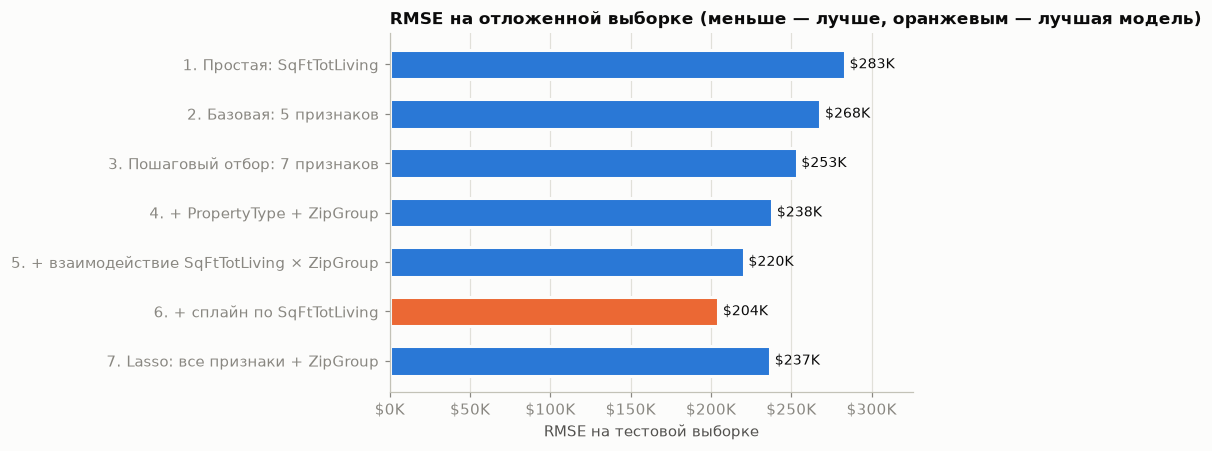

In [40]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
names = comparison.index[::-1]
vals = comparison["RMSE (test)"][::-1]
best = vals.idxmin()
ax.barh(names, vals, height=0.6, color=[PAL["orange"] if n == best else PAL["blue"] for n in names],
        edgecolor=PAL["surface"], lw=2)
for yv, v in enumerate(vals):
    ax.text(v + 3000, yv, f"${v / 1e3:,.0f}K", va="center", fontsize=9)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, vals.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE на тестовой выборке")
ax.set_title("RMSE на отложенной выборке (меньше — лучше, оранжевым — лучшая модель)")
fig.tight_layout()
save(fig, "13_model_comparison")

- Лучшая модель — **6**, со сплайном по площади и его взаимодействием с группой индексов:
  RMSE $204K, MAE $104K, R² = 0.735 на тестовой выборке.
- Основной прирост дают местоположение и его взаимодействие с площадью: каждый из шагов
  3 → 4 → 5 → 6 снижает RMSE на $15–18K.
- Lasso на всех признаках с `ZipGroup` (RMSE $237K) соответствует модели 4 без
  взаимодействий: регуляризация не заменяет правильно заданную форму зависимости.
- RMSE на тестовой выборке выше обучающей лишь на $6–9K для всех моделей — признаков
  переобучения нет.

## 12. Итоги

**Главный результат.** На отложенной выборке лучшая модель — линейная регрессия со сплайном
по жилой площади, взаимодействующим с группой почтовых индексов: **RMSE $204K, R² = 0.735**
против RMSE $268K и R² = 0.545 у базовой модели из пяти признаков.

**Что определяет цену:**
- **жилая площадь** — главный признак; цена квадратного фута зависит от района: от $115
  в самой дешёвой группе индексов до $341 в самой дорогой;
- **местоположение** — главный смешивающий фактор: без него коэффициенты площади участка,
  числа ванных и типа недвижимости получают противоположный знак;
- **класс постройки** — +$106K за ступень в базовой модели;
- **спальни** при той же площади снижают цену (−$42K за спальню с учётом района):
  больше спален означает меньшие комнаты;
- связь площади с ценой **нелинейна**: сплайны и GAM улучшают модель.

**Диагностика.** Остатки гетероскедастичны и имеют тяжёлые хвосты: модель хуже всего
описывает дорогие дома. На небольшой выборке несколько влиятельных наблюдений заметно
меняют коэффициенты; среди выбросов встречаются сделки, не похожие на рыночные.

**Ограничения**
- Модели разделов 3–10 оценены на обучающих данных; на отложенной выборке проверены модели
  раздела 11.
- `ZipGroup` построен по остаткам модели, то есть по ценам. В разделах 6–7 он рассчитан по
  всем данным, в разделе 11 — только по обучающей части.
- Распределение цен скошено, и ошибка в долларах определяется дорогими домами; модель для
  логарифма цены дала бы более равномерную относительную точность.
- Признаки `LandVal` и `ImpsVal` (налоговая оценка земли и построек) не использовались:
  это оценка той же недвижимости, а не её характеристика.
- Проверка на более позднем периоде не проводилась: цены приведены к единому уровню
  индексом, но модель обучалась на сделках всех лет сразу.